In [1]:
### follow the file to analyze generic cubic and linear band spectrum 

In [104]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
#import Minimal_Model_2D as mm2d
import time

np.set_printoptions(threshold=sys.maxsize)
#from Minimal_Model_1D import *

#import Minimal_Model_1D as M

from Minimal_Model_1D import *


In [105]:
class modified_spin_orbit(oneD_Minimal_Model):

    def spin_orbit(self, i, j, s, so='cu', kx=0):

        """
        returns  <i,s|H_SO|j,sp>
        
        Args:
            i, j (int): refers to i and j th y subband sho wavefunction 
            s, sp (int){0 or 1}: refers to spin index up and down resp. for spin orbit, sp is opposite of s for spin orbit to be non zero
            so : spin orbit coupling, 'cu' if cubic rashba, 'li' if linear rashba
        
        """

        if so == 'cu':
            #print('cu')
            # cubic SOC #

            #k_minus_cube = self.onedOP.KxCu(kx)*self.Ky_iden_pr(i,j) - 1j*3*self.onedOP.KxSq(kx)*self.Ky_pr(i,j) - 3*self.onedOP.Kx(kx)*self.Kysq_pr(i,j) + 1j*self.Kycube_pr(i,j)*self.onedOP.iden()
            #k_plus_cube =  self.onedOP.KxCu(kx)*self.Ky_iden_pr(i,j) + 1j*3*self.onedOP.KxSq(kx)*self.Ky_pr(i,j) - 3*self.onedOP.Kx(kx)*self.Kysq_pr(i,j) - 1j*self.Kycube_pr(i,j)*self.onedOP.iden() 

            ### simplified cubic ###
            k_minus_cube = self.onedOP.KxCu(kx)*self.Ky_iden_pr(i,j) - 1j*3*self.onedOP.KxSq(kx)*self.Ky_pr(i,j) - 3*self.onedOP.Kx(kx)*self.Kysq_pr(i,j) + 1j*self.Kycube_pr(i,j)*self.onedOP.iden()
            k_plus_cube =  self.onedOP.KxCu(kx)*self.Ky_iden_pr(i,j) + 1j*3*self.onedOP.KxSq(kx)*self.Ky_pr(i,j) - 3*self.onedOP.Kx(kx)*self.Kysq_pr(i,j) - 1j*self.Kycube_pr(i,j)*self.onedOP.iden() 


            ### Note in later definitions, soc coupling is evoked only when s!=s' ###
            ### Hence not coding that statement here ###  

            if s==0:
                
                return -1j*self.alphat*k_minus_cube
            
            else:

                return 1j*self.alphat*k_plus_cube

        elif so == 'li':
            #print('li')
            # Linear SOC #

            if i==j:

                ### Note in later definitions, soc coupling is evoked only when s!=s' ###
                ### Hence not coding that statement here ###
                if s ==0 : 

                    return 1j*self.alphat*(self.onedOP.Kx(kx))
                
                else:

                    return -1j*self.alphat*(self.onedOP.Kx(kx))
                
            else :

                return self.alphat*(self.Ky_pr(i,j))*self.onedOP.iden()      
        
        else:

            return self.onedOP.zer()

0
50
100
150
200


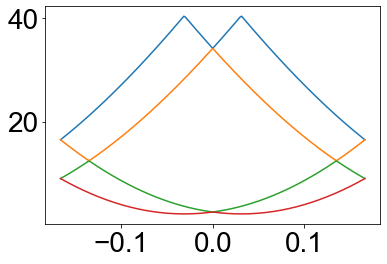

In [106]:
N = 6
NSM = 2
NSC = 2
MY = 1
AX = 1
OMEGA = 5 #IN MEv
ALPHAT = 7.5


M_per = modified_spin_orbit(N, NSM, NSC, MY, AX, OMEGA, ALPHAT, px=True)

KX = np.linspace(-math.pi/6, math.pi/6, 201)

KNUM = 4


Ep_one_band = np.empty((KX.shape[0],KNUM))

for i in range(KX.shape[0]):

    H = M_per.HN(so='li', kx=KX[i])

    E = eigsh(H, k=KNUM, return_eigenvectors=False, which='SA')

    #Es = np.sort(E)

    Ep_one_band[i, :] = E

    if i%50 == 0:

        print(i)


plt.plot(KX/np.pi, Ep_one_band)

np.save("linear_spectrum_first_4_energies_one_subband_alphat_{}.npy".format(ALPHAT) , Ep_one_band)    


0
50
100
150
200


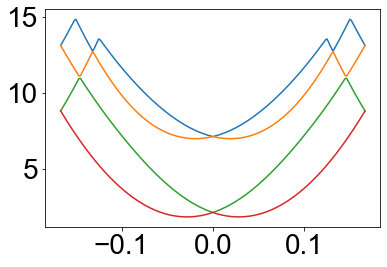

In [107]:
N = 6
NSM = 2
NSC = 2
MY = 5
AX = 1
OMEGA  = 5  #IN MEv
#OMEGA = 15 #IN MEv
ALPHAT = 7.5


M_per = modified_spin_orbit(N, NSM, NSC, MY, AX, OMEGA, ALPHAT, px=True)

KX = np.linspace(-math.pi/6, math.pi/6, 201)

KNUM = 4

Ep = np.empty((KX.shape[0],KNUM))

for i in range(KX.shape[0]):

    H = M_per.HN(so='li', kx=KX[i])

    E = eigsh(H, k=KNUM, return_eigenvectors=False, which='SA')

    #Es = np.sort(E)

    Ep[i, :] = E

    if i%50 == 0:

        print(i)


plt.plot(KX/np.pi, Ep)


np.save("linear_spectrum_first_4_energies_five_subband_alphat_{}.npy".format(ALPHAT) , Ep)    
#plt.ylim(ymin=-10460, ymax = -10350)
#plt.xlim(xmin= -0.05, xmax=0.05)

(-0.5, 0.5)

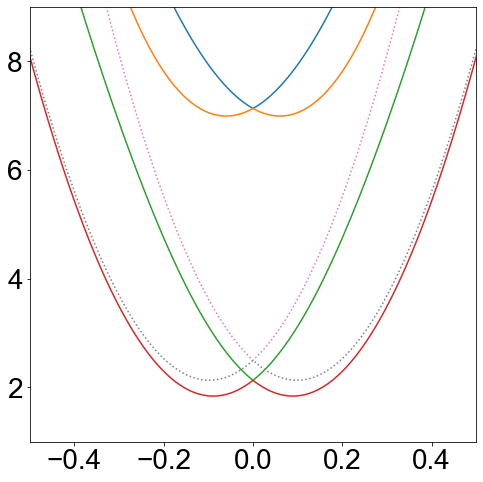

In [108]:
plt.figure(figsize=(8,8))
plt.plot(KX, Ep)
plt.plot(KX, Ep_one_band, linestyle='dotted')
plt.ylim(ymin=1, ymax=9)
plt.xlim(xmin=-0.5, xmax=0.5)
#plt.aspect_ratio

(0.0, 0.5)

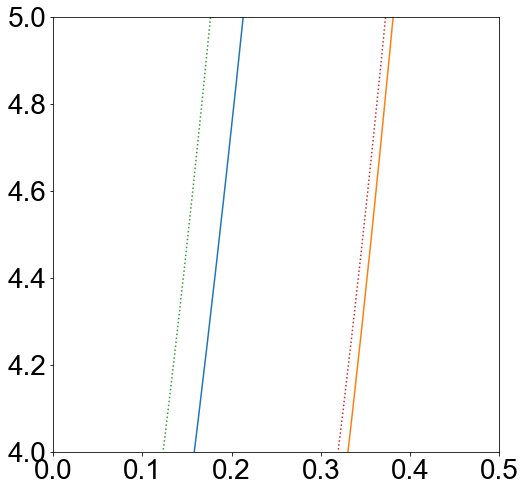

In [109]:
plt.figure(figsize=(8,8))
plt.plot(KX, Ep[:,2:4])
plt.plot(KX, Ep_one_band[:,2:4], linestyle='dotted')
plt.ylim(ymin=4, ymax=5)
plt.xlim(xmin=0, xmax=0.5)

In [110]:
### finding points closest to -2300 on red curve above +ve k 

number = 4.5

midpoint = len(KX) // 2

print(np.shape(Ep[midpoint:, 2]))

temp_diff = np.abs(Ep[midpoint:, 2] - number)

# Get the indices of the 5 smallest differences
closest_indices = np.argpartition(temp_diff, 5)[:5]

closest_indices = np.sort(closest_indices)

print(closest_indices)


slope = np.empty(closest_indices.shape[0]-1)

Ep_after_mid_solid1 = Ep[midpoint:, 2]

KX_after_mid = KX[midpoint:]

print(Ep_after_mid_solid1[closest_indices])

for i in range(closest_indices.shape[0]-1):

    di = closest_indices[i]
    df = closest_indices[i+1]

    slope[i] = (Ep_after_mid_solid1[di] - Ep_after_mid_solid1[di+1])/(KX_after_mid[di] - KX_after_mid[di+1])


print(slope)

ind1 = closest_indices[2]

x0 = KX_after_mid[ind1]
y0 = Ep_after_mid_solid1[ind1]
sl0 = (slope[1]+ slope[2])/2

x = np.linspace(x0 + 0.01*np.pi, x0 - 0.01*np.pi, 21 )

vf1_solid = sl0*(x-x0) + y0

print("for solid line 1", "closest index: ", ind1,"slope of fermiline:", sl0)

(101,)
[34 35 36 37 38]
[4.34380933 4.4381507  4.53393632 4.63114202 4.72974327]
[18.01787458 18.293706   18.56492124 18.83145228]
for solid line 1 closest index:  36 slope of fermiline: 18.42931362025177


In [111]:
### finding points closest to -2300 on red curve above +ve k 

number = 4.5

midpoint = len(KX) // 2

print(np.shape(Ep[midpoint:, 3]))

temp_diff = np.abs(Ep[midpoint:, 3] - number)

# Get the indices of the 5 smallest differences
closest_indices = np.argpartition(temp_diff, 5)[:5]

closest_indices = np.sort(closest_indices)

print(closest_indices)


slope = np.empty(closest_indices.shape[0]-1)

Ep_after_mid_solid2 = Ep[midpoint:, 3]

KX_after_mid = KX[midpoint:]

print(Ep_after_mid_solid2[closest_indices])

for i in range(closest_indices.shape[0]-1):

    di = closest_indices[i]
    df = closest_indices[i+1]

    slope[i] = (Ep_after_mid_solid2[di] - Ep_after_mid_solid2[di+1])/(KX_after_mid[di] - KX_after_mid[di+1])


print(slope)


ind = closest_indices[2]

x0 = KX_after_mid[ind]

x_vf2_solid = np.linspace(x0 + 0.01*np.pi, x0 - 0.01*np.pi, 21 )
y_vf2_solid = Ep_after_mid_solid2[ind]

sl_vf2_solid = (slope[1]+ slope[2])/2

vf2_solid = sl_vf2_solid*(x_vf2_solid-x0) + y_vf2_solid

print("for solid line 2", "closest index: ", ind,"slope of fermiline:", sl_vf2_solid)

(101,)
[66 67 68 69 70]
[4.28183788 4.38252749 4.48522952 4.58994167 4.69666156]
[19.23029915 19.61464393 19.9985474  20.38199638]
for solid line 2 closest index:  68 slope of fermiline: 19.806595664928807


In [112]:
### finding points closest to -2300 on red curve above +ve k 

number = 4.5

midpoint = len(KX) // 2

print(np.shape(Ep_one_band[midpoint:, 2]))

temp_diff = np.abs(Ep_one_band[midpoint:, 2] - number)

# Get the indices of the 5 smallest differences
closest_indices = np.argpartition(temp_diff, 5)[:5]

closest_indices = np.sort(closest_indices)

print(closest_indices)


slope = np.empty(closest_indices.shape[0]-1)

Ep_after_mid_dashed1 = Ep_one_band[midpoint:, 2]

KX_after_mid = KX[midpoint:]

print(Ep_after_mid_dashed1[closest_indices])

for i in range(closest_indices.shape[0]-1):

    di = closest_indices[i]
    df = closest_indices[i+1]

    slope[i] = (Ep_after_mid_dashed1[di] - Ep_after_mid_dashed1[di+1])/(KX_after_mid[di] - KX_after_mid[di+1])


print(slope)

ind = closest_indices[2]

x0 = KX_after_mid[ind]

x_vf1_dashed = np.linspace(x0 + 0.01*np.pi, x0 - 0.01*np.pi, 21 )
y_vf1_dashed = Ep_after_mid_dashed1[ind]

sl_vf1_dashed = (slope[1]+ slope[2])/2

vf1_dashed = sl_vf1_dashed*(x_vf1_dashed-x0) + y_vf1_dashed

print("for solid line 2", "closest index: ", ind,"slope of fermiline:", sl_vf1_dashed)

(101,)
[27 28 29 30 31]
[4.3176028  4.4137659  4.51196736 4.6122045  4.71447457]
[18.36579789 18.75509801 19.14388395 19.53214504]
for solid line 2 closest index:  29 slope of fermiline: 18.94949097684308


In [113]:
### finding points closest to -2300 on red curve above +ve k 

number = 4.5

midpoint = len(KX) // 2

print(np.shape(Ep_one_band[midpoint:, 3]))

temp_diff = np.abs(Ep_one_band[midpoint:, 3] - number)

# Get the indices of the 5 smallest differences
closest_indices = np.argpartition(temp_diff, 5)[:5]

closest_indices = np.sort(closest_indices)

print(closest_indices)


slope = np.empty(closest_indices.shape[0]-1)

Ep_after_mid_dashed2 = Ep_one_band[midpoint:, 3]

KX_after_mid = KX[midpoint:]

print(Ep_after_mid_dashed2[closest_indices])

for i in range(closest_indices.shape[0]-1):

    di = closest_indices[i]
    df = closest_indices[i+1]

    slope[i] = (Ep_after_mid_dashed2[di] - Ep_after_mid_dashed2[di+1])/(KX_after_mid[di] - KX_after_mid[di+1])


print(slope)

ind = closest_indices[2]

x0 = KX_after_mid[ind]

x_vf2_dashed = np.linspace(x0 + 0.01*np.pi, x0 - 0.01*np.pi, 21 )
y_vf2_dashed = Ep_after_mid_dashed2[ind]

sl_vf2_dashed = (slope[1]+ slope[2])/2

vf2_dashed = sl_vf2_dashed*(x_vf2_dashed-x0) + y_vf2_dashed

print("for solid line 2", "closest index: ", ind,"slope of fermiline:", sl_vf2_dashed)

(101,)
[64 65 66 67 68]
[4.27562412 4.37088271 4.46818084 4.56751585 4.66888501]
[18.19304967 18.58257432 18.97158952 19.36008461]
for solid line 2 closest index:  66 slope of fermiline: 18.777081920913844


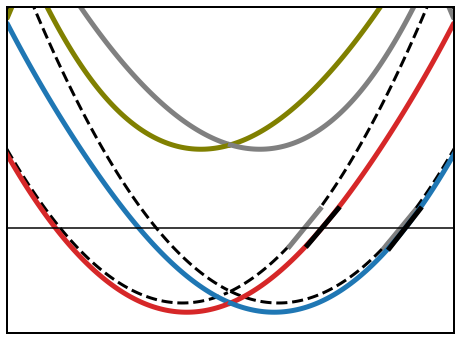

In [130]:
# Define constants
midpoint = len(KX) // 2

chemical_potential = 4.5

Ep_new = Ep- 4.5

Ep_one_band_new = Ep_one_band-4.5 
# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'
plt.rc('font', size=28)

fig, ax = plt.subplots(figsize=(8, 6))

# Dashed lines for Ep_one_band columns
ax.plot(KX[:midpoint] / np.pi, Ep_one_band_new[:midpoint, 2], ls='dashed', color='black', lw=3)
ax.plot(KX[midpoint:] / np.pi, Ep_one_band_new[midpoint:, 2], ls='dashed', color='black', lw=3)
ax.plot(KX[:midpoint] / np.pi, Ep_one_band_new[:midpoint, 3], ls='dashed', color='black', lw=3)
ax.plot(KX[midpoint:] / np.pi, Ep_one_band_new[midpoint:, 3], ls='dashed', color='black', lw=3)
ax.plot(x_vf1_dashed / np.pi, vf1_dashed - 4.5, color='grey', lw=5)

# Additional plots for Ep columns with specific colors
ax.plot(KX[:midpoint] / np.pi, Ep_new[:midpoint, 0], color='#808080', lw=5)
ax.plot(KX[midpoint:] / np.pi, Ep_new[midpoint:, 0], color='#808000', lw=5)
ax.plot(KX[:midpoint] / np.pi, Ep_new[:midpoint, 1], color='#808000', lw=5)
ax.plot(KX[midpoint:] / np.pi, Ep_new[midpoint:, 1], color='#808080', lw=5)
ax.plot(x_vf2_dashed / np.pi, vf2_dashed - 4.5, color='grey', lw=5)


# Plot Ep columns before and after midpoint with color schemes
ax.plot(KX[:midpoint] / np.pi, Ep_new[:midpoint, 2], color='#1F77B4', lw=5)
ax.plot(KX[midpoint:] / np.pi, Ep_new[midpoint:, 2], color='#D62728', lw=5)
ax.plot(x / np.pi, vf1_solid - 4.5, color='black', lw=5)
#ax.text(0.065, 0.3, r'$v_{f1}$', fontsize=28)

ax.plot(KX[:midpoint] / np.pi, Ep_new[:midpoint, 3], color='#D62728', lw=5)
ax.plot(KX[midpoint:] / np.pi, Ep_new[midpoint:, 3], color='#1F77B4', lw=5)
ax.plot(x_vf2_solid / np.pi, vf2_solid - 4.5, color='black', lw=5)
#ax.text(0.12, 0.3, r'$v_{f2}$', fontsize=28)


# Horizontal dotted line at y=4.5
#ax.axhline(y=4.5, color='black', linestyle='dotted')

# Annotation for vf1 != vf2
#ax.text(-0.03, 1.8, r'$v_{f1} \neq v_{f2}$', fontsize=28)

ax.axhline(y=-4.0 + 4.0, color = 'black', linestyle='solid')


ax.spines['top'].set_visible(True)
ax.spines['right'].set_visible(True)
ax.spines['left'].set_visible(True)
ax.spines['bottom'].set_visible(True)

# Customize the spines' appearance (optional)
for spine in ax.spines.values():
    spine.set_linewidth(2)  # Set the thickness of the box
    spine.set_color('black')  # Set the color of the box

# Vertical and horizontal arrows
#ax.annotate('', xy=(0, 10.7), xytext=(0, 2.1), arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.5))
#ax.annotate('', xy=(0.13, 2.2), xytext=(-0.13, 2.2), arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.5))
#ax.text(0.005, 10, r'$E$', fontsize=28)
#ax.text(0.125, 2.5, r'$k_{x}$', fontsize=28)

# Set x and y axis limits
ax.set_xlim(xmin=-0.145, xmax=0.145)
ax.set_ylim(ymax=11-4.0)

# Set x and y labels
#ax.set_ylabel("Energy, $E$", fontsize=28)
#ax.set_xlabel(r"wavevector, $k_{x}$", fontsize=28)

# Customize ticks: remove all x ticks and only show y=0
ax.set_xticks([])  # Remove all x-axis ticks
ax.set_yticks([])  # Only keep y-axis tick at 0
ax.tick_params(axis='both', which='both', length=0)  # Hide both-axis tick marks

plt.savefig('linear_spectrum.png', dpi=300, bbox_inches='tight')

# Display the plot
plt.show()



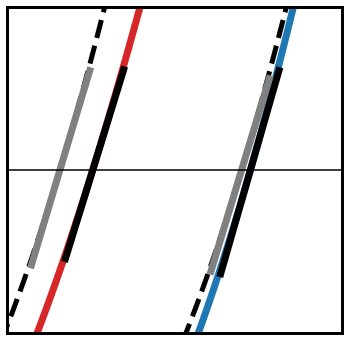

In [128]:
# Define constants
midpoint = len(KX) // 2

chemical_potential = 4.5

Ep_new = Ep- 4.5

Ep_one_band_new = Ep_one_band-4.5 
# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'
plt.rc('font', size=28)

fig, ax = plt.subplots(figsize=(6, 6))

# Plot Ep columns before and after midpoint with color schemes
ax.plot(KX[:midpoint] / np.pi, Ep_new[:midpoint, 2], color='#1F77B4', lw=7)
ax.plot(KX[midpoint:] / np.pi, Ep_new[midpoint:, 2], color='#D62728', lw=7)
ax.plot(x / np.pi, vf1_solid - 4.5, color='black', lw=7)
#ax.text(0.065, 0.3, r'$v_{f1}$', fontsize=28)

ax.plot(KX[:midpoint] / np.pi, Ep_new[:midpoint, 3], color='#D62728', lw=7)
ax.plot(KX[midpoint:] / np.pi, Ep_new[midpoint:, 3], color='#1F77B4', lw=7)
ax.plot(x_vf2_solid / np.pi, vf2_solid - 4.5, color='black', lw=7)
#ax.text(0.12, 0.3, r'$v_{f2}$', fontsize=28)

# Dashed lines for Ep_one_band columns
ax.plot(KX[:midpoint] / np.pi, Ep_one_band_new[:midpoint, 2], ls='dashed', color='black', lw=5)
ax.plot(KX[midpoint:] / np.pi, Ep_one_band_new[midpoint:, 2], ls='dashed', color='black', lw=5)
ax.plot(KX[:midpoint] / np.pi, Ep_one_band_new[:midpoint, 3], ls='dashed', color='black', lw=5)
ax.plot(KX[midpoint:] / np.pi, Ep_one_band_new[midpoint:, 3], ls='dashed', color='black', lw=5)
ax.plot(x_vf1_dashed / np.pi, vf1_dashed - 4.5, color='grey', lw=7)

# Additional plots for Ep columns with specific colors
ax.plot(KX[:midpoint] / np.pi, Ep_new[:midpoint, 0], color='#808080', lw=5)
ax.plot(KX[midpoint:] / np.pi, Ep_new[midpoint:, 0], color='#808000', lw=5)
ax.plot(KX[:midpoint] / np.pi, Ep_new[:midpoint, 1], color='#808000', lw=5)
ax.plot(KX[midpoint:] / np.pi, Ep_new[midpoint:, 1], color='#808080', lw=5)
ax.plot(x_vf2_dashed / np.pi, vf2_dashed - 4.5, color='grey', lw=7)

# Horizontal dotted line at y=4.5
#ax.axhline(y=4.5, color='black', linestyle='dotted')

# Annotation for vf1 != vf2
#ax.text(-0.03, 1.8, r'$v_{f1} \neq v_{f2}$', fontsize=28)

ax.axhline(y=-4.0 + 4.0, color = 'black', linestyle='solid')


ax.spines['top'].set_visible(True)
ax.spines['right'].set_visible(True)
ax.spines['left'].set_visible(True)
ax.spines['bottom'].set_visible(True)

# Customize the spines' appearance (optional)
for spine in ax.spines.values():
    spine.set_linewidth(3)  # Set the thickness of the box
    spine.set_color('black')  # Set the color of the box

# Vertical and horizontal arrows
#ax.annotate('', xy=(0, 10.7), xytext=(0, 2.1), arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.5))
#ax.annotate('', xy=(0.13, 2.2), xytext=(-0.13, 2.2), arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.5))
#ax.text(0.005, 10, r'$E$', fontsize=28)
#ax.text(0.125, 2.5, r'$k_{x}$', fontsize=28)

# Set x and y axis limits
ax.set_xlim(xmin=0.03, xmax=0.145)
ax.set_ylim(ymax=1, ymin=-1)

# Set x and y labels
#ax.set_ylabel("Energy, $E$", fontsize=28)
#ax.set_xlabel(r"wavevector, $k_{x}$", fontsize=28)

# Customize ticks: remove all x ticks and only show y=0
ax.set_xticks([])  # Remove all x-axis ticks
ax.set_yticks([])  # Only keep y-axis tick at 0
ax.tick_params(axis='both', which='both', length=0)  # Hide both-axis tick marks

plt.savefig('linear_spectrum_zoom.png', dpi=300, bbox_inches='tight')

# Display the plot
plt.show()
